# 实验 03：固定同一个 PINN，定位误差界的保守性

本笔记嵌入实验 02 的最终权重，无需重新训练或读取其他文件。问题仍为 $-u''=2$，区间 $[0,1]$，零 Dirichlet 边界。

只改变认证方法：全域或局部导数界 × 统一最大残差或空间加权残差。全部方法使用同一组 1001 个残差检查点。

基线是 $\eta=(R_{\rm grid}+Mh/2)/8$。下文是经典比较原理和 Green 函数的应用，不宣称新理论。所有区间界在精确实数算术下有效；本代码使用普通 float64，没有向外舍入，因此输出是理论上界的数值实现，而非机器级严格证书。


In [1]:
import json
import time
import numpy as np
import matplotlib.pyplot as plt
weights = json.loads('{"hidden.weight": [[-0.11655703152469872], [-0.2018080591461949], [0.4583162375718069], [0.20026538914519], [0.7756982500749172], [0.6742251714702365], [-0.23886249891440564], [-0.015972329244446814], [0.15495054929215127], [0.40925202029437746], [-1.064355372348248], [-0.7289114586982176], [-0.432126169361768], [-0.9753575808091411], [-0.5797251397767852], [0.413016653300717]], "hidden.bias": [-0.7964742364253344, 1.04609497315135, -0.8985656108997572, 0.8314479318949629, 0.658896077752849, 0.551308758724174, 0.4390765902847739, -0.5133502497582167, 0.6643002332227377, 0.629175889664992, 0.706121480684401, 0.8927699184593991, -0.9348675289884024, 0.9050058336419343, 0.2240944649313563, -0.9513698462038765], "output.weight": [[-0.06861713988529242, 0.23739684108928555, -0.15106505846447962, -0.07831394517377012, -0.03707287650474282, -0.09767832746735168, 0.18557952082528661, -0.2039472044479674, 0.09590278924364797, 0.3183226149593691, 0.04467755812652954, -0.1016417179081969, -0.26398918915600494, -0.09612154461026647, 0.024498051289461024, -0.16009472903431574]], "output.bias": [0.17573307305441363]}')
w = np.array(weights['hidden.weight']).flatten()
b = np.array(weights['hidden.bias'])
a = np.array(weights['output.weight']).flatten()
c = weights['output.bias'][0]

def fields(x):
    x = np.asarray(x)
    t = np.tanh(x[..., None]*w+b)
    n = c + t@a
    n1 = ((1-t*t)*(a*w)).sum(axis=-1)
    n2 = ((-2*t+2*t**3)*(a*w**2)).sum(axis=-1)
    n3 = ((-2+8*t*t-6*t**4)*(a*w**3)).sum(axis=-1)
    q=x*(1-x)
    qp=1-2*x
    v=q*n
    v2=q*n2+2*qp*n1-2*n
    v3=q*n3+3*qp*n2-6*n1
    return v, -v2-2, -v3

global_M = 6*np.sum(abs(a*w)) + 6*np.sum(abs(a)*w**2) + 0.5*np.sum(abs(a)*abs(w)**3)
x_error=np.linspace(0,1,10001)
v_error, _, _=fields(x_error)
reference_error=np.max(abs(v_error-x_error*(1-x_error)))
assert np.isclose(reference_error, 2.6974090221676406e-5, atol=1e-13, rtol=0)
print('Reused weights; no training was performed.')
print(f'Reference-grid error: {reference_error:.10e}')
print(f'Original global derivative bound M: {global_M:.8f}')


Reused weights; no training was performed.
Reference-grid error: 2.6974090222e-05
Original global derivative bound M: 7.93823056


## 1. 在小区间上保留导数的符号和输入范围

每个神经元在区间 $I=[l,u]$ 的输入范围可从已知权重直接计算。令 $t=\tanh(wx+b)$，则

$$\sigma'=1-t^2,\quad \sigma''=-2t+2t^3,\quad \sigma^{(3)}=-2+8t^2-6t^4.$$

这些多项式在闭区间上的极值出现在端点或已知的驻点。计算其范围，再按区间运算传播至 $v^{(3)}=qN^{(3)}+3q'N''-6N'$，即可得到该小区间的 $M_i$。

这一步不靠导数采样来宣称全域保证，也不需要第四阶导数。区间运算可能过宽，但数学上的包含性质成立。


In [2]:
def poly(t, order):
    if order == 1: return 1-t*t
    if order == 2: return -2*t+2*t**3
    return -2+8*t*t-6*t**4

def activation_derivative_range(lo, hi, order):
    left, right = poly(lo,order), poly(hi,order)
    lower, upper = np.minimum(left,right), np.maximum(left,right)
    roots = {1:[0.0], 2:[-1/np.sqrt(3),1/np.sqrt(3)],
             3:[-np.sqrt(2/3),0.0,np.sqrt(2/3)]}[order]
    for z in roots:
        inside=(lo<=z)&(z<=hi)
        value=poly(z,order)
        lower=np.where(inside,np.minimum(lower,value),lower)
        upper=np.where(inside,np.maximum(upper,value),upper)
    return lower, upper

def interval_mul(l1,u1,l2,u2):
    p=np.array([l1*l2,l1*u2,u1*l2,u1*u2])
    return p.min(axis=0),p.max(axis=0)

def local_derivative_bounds(nodes):
    left,right=nodes[:-1],nodes[1:]
    z1=left[:,None]*w+b
    z2=right[:,None]*w+b
    tl=np.tanh(np.minimum(z1,z2))
    tu=np.tanh(np.maximum(z1,z2))
    n_ranges=[]
    for order in [1,2,3]:
        sl,su=activation_derivative_range(tl,tu,order)
        coeff=a*w**order
        n_ranges.append((np.minimum(sl*coeff,su*coeff).sum(axis=1),
                         np.maximum(sl*coeff,su*coeff).sum(axis=1)))
    ql=np.minimum(left*(1-left),right*(1-right))
    qu=np.maximum(left*(1-left),right*(1-right))
    qu=np.where((left<=0.5)&(right>=0.5),0.25,qu)
    qpl,qpu=1-2*right,1-2*left
    t3=interval_mul(ql,qu,*n_ranges[2])
    t2=interval_mul(qpl,qpu,*n_ranges[1])
    lower=t3[0]+3*t2[0]-6*n_ranges[0][1]
    upper=t3[1]+3*t2[1]-6*n_ranges[0][0]
    return np.maximum(abs(lower),abs(upper))


## 2. 空间加权：不同位置的残差对解误差的影响不同

对于当前零边界问题，有经典 Green 表示：
$$e(x)=\int_0^1G(x,s)r(s)\,ds,\qquad G(x,s)=\min(x,s)(1-\max(x,s))\geq0.$$

因此，如果每个小区间上 $|r|\leq\varepsilon_i$，把这些上界拼成分段常数函数 $\bar\varepsilon(s)$，就有
$$|e(x)|\leq B(x)=\int_0^1G(x,s)\bar\varepsilon(s)\,ds.$$

只需求 $-B''=\bar\varepsilon$、$B(0)=B(1)=0$。因为右端分段常数，$B$ 是分段二次函数，其每段极值可直接求出，无需对 Green 积分做未经控制的数值求积。每段残差界取
$$\varepsilon_i=\max(|r(x_i)|,|r(x_{i+1})|)+M_i h_i/2.$$

边界附近的 Green 权重较小。统一使用 $\varepsilon/8$ 相当于把整个区域都替换成最坏残差，丢失了这种空间信息。

Green 表示的一般原理参考：https://www.math.cmu.edu/~gautam/c/2026-632/notes/greens-functions.html


In [3]:
def envelope_maximum(nodes, eps):
    h=np.diff(nodes)
    mid=(nodes[:-1]+nodes[1:])/2
    slope=np.sum(eps*h*(1-mid))
    value=0.0
    maximum=0.0
    trace=[0.0]
    for width, forcing in zip(h,eps):
        t=np.clip(slope/forcing,0,width) if forcing>0 else (width if slope>0 else 0)
        maximum=max(maximum, value+slope*t-0.5*forcing*t*t)
        value += slope*width-0.5*forcing*width*width
        slope -= forcing*width
        trace.append(value)
    assert abs(value)<1e-12
    return maximum,np.array(trace)

nodes=np.linspace(0,1,1001)
h=np.diff(nodes)
_,r_nodes,_=fields(nodes)
local_M=local_derivative_bounds(nodes)
_,_,rp_mid=fields((nodes[:-1]+nodes[1:])/2)
assert np.all(abs(rp_mid)<=local_M+1e-12)
endpoint_max=np.maximum(abs(r_nodes[:-1]),abs(r_nodes[1:]))
eps_global=endpoint_max+global_M*h/2
eps_local=endpoint_max+local_M*h/2

green_global,trace_global=envelope_maximum(nodes,eps_global)
green_local,trace_local=envelope_maximum(nodes,eps_local)
methods=[
    ('Global M + uniform residual', np.max(eps_global)/8),
    ('Local M + uniform residual', np.max(eps_local)/8),
    ('Global M + Green envelope', green_global),
    ('Local M + Green envelope', green_local),
]
print('All methods: same fixed weights and 1001 residual samples')
print('method                              bound          bound / reference')
for name,eta in methods:
    assert eta>=reference_error-1e-12
    print(f'{name:34s} {eta:13.7e} {eta/reference_error:18.4f}')
print(f'Maximum of local derivative bounds: {local_M.max():.8f}')
_,_,rp_dense=fields(x_error)
print(f'Derivative maximum observed on dense grid: {np.max(abs(rp_dense)):.8f}')
print(f'Global M / max local bound: {global_M/local_M.max():.3f}')
print(f'Max sampled residual at x={nodes[np.argmax(abs(r_nodes))]:.5f}')

# 与旧实验交叉检查。解析极值位置可能不在网格，下面仅为实现检查。
assert np.isclose(methods[0][1],0.0014159097093060303,atol=1e-12,rtol=0)
assert green_local<=methods[1][1]+1e-12
assert green_local<=green_global+1e-12
assert methods[1][1]<=methods[0][1]+1e-12

# 校验分段包络积分：常数源项 2 应得到 B=x(1-x)，最大值 1/4。
test_nodes=np.array([0.0,0.1,0.3,0.9,1.0])
test_max,test_trace=envelope_maximum(test_nodes,np.full(4,2.0))
assert np.isclose(test_max,0.25,atol=1e-14)
assert np.allclose(test_trace,test_nodes*(1-test_nodes),atol=1e-14)
# 在每个区间额外检查 11 个点，发现区间实现错误；采样不替代理论证明。
test_x=nodes[:-1,None]+h[:,None]*np.linspace(0,1,11)[None,:]
_,test_r,test_rp=fields(test_x)
assert np.all(abs(test_rp)<=local_M[:,None]+1e-12)
assert np.all(abs(test_r)<=eps_local[:,None]+1e-12)
print('Checks passed: old baseline, analytic envelope example, interval bounds at independent points.')


All methods: same fixed weights and 1001 residual samples
method                              bound          bound / reference
Global M + uniform residual        1.4159097e-03            52.4915
Local M + uniform residual         9.2800690e-04            34.4036
Global M + Green envelope          6.5330548e-04            24.2197
Local M + Green envelope           1.5831685e-04             5.8692
Maximum of local derivative bounds: 0.13178559
Derivative maximum observed on dense grid: 0.13093384
Global M / max local bound: 60.236
Max sampled residual at x=1.00000
Checks passed: old baseline, analytic envelope example, interval bounds at independent points.


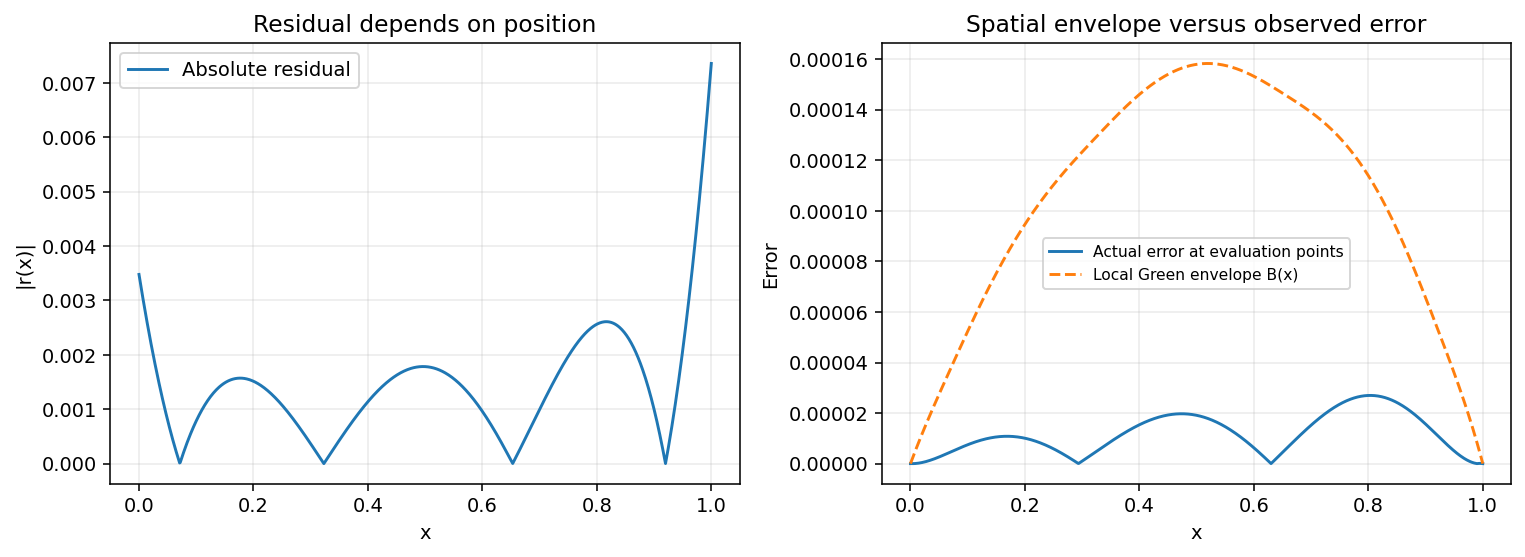

In [4]:
v_plot,_,_=fields(nodes)
e_plot=v_plot-nodes*(1-nodes)
fig,axes=plt.subplots(1,2,figsize=(11,4.1))
axes[0].plot(nodes,abs(r_nodes),label='Absolute residual')
axes[0].set(title='Residual depends on position',xlabel='x',ylabel='|r(x)|')
axes[0].legend()
axes[1].plot(nodes,abs(e_plot),label='Actual error at evaluation points')
axes[1].plot(nodes,trace_local,'--',label='Local Green envelope B(x)')
axes[1].set(title='Spatial envelope versus observed error',xlabel='x',ylabel='Error')
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## 3. 怎样解释这些结果

- 四种方法构成 2×2 对照，避免同时改变求解器、训练步数、配点数。
- 更紧的局部导数界主要减少点间覆盖修正；它不能单独解决统一最大残差估计的保守性。
- Green 包络利用残差空间分布。它还取了残差绝对值，因此仍丢失正负抵消信息。
- 本次是一个简单问题、一个训练种子的诊断。不能据此宣称普遍改进或新研究贡献。后续应扩展源项、训练种子、训练程度，并记录相同容差下认证的成本。
- 这些公式的构造不调用精确解；精确解仅用于事后验证。评估指标中的真实误差仍采用密集网格参考值；可用之前讨论的插值误差界包住遗漏量。
- 要形成机器级严格数值证书，需要向外舍入的区间计算，且包住残差求值和包络最大值计算中的误差。
